<a href="https://colab.research.google.com/github/The-Harsh-07/ML-CIE-1-Activity-AD3121/blob/main/unit%202/ML_CIE_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
california = fetch_california_housing(as_frame=True)
df = california.frame

In [16]:
print("--- Step 2: Data Inspection ---\n")

print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print("\nColumn Names and Data Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())

--- Step 2: Data Inspection ---

Rows: 20640, Columns: 9

Column Names and Data Types:
 MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Missing Values:
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [6]:
X = df[['MedInc']]
y = df['MedHouseVal']

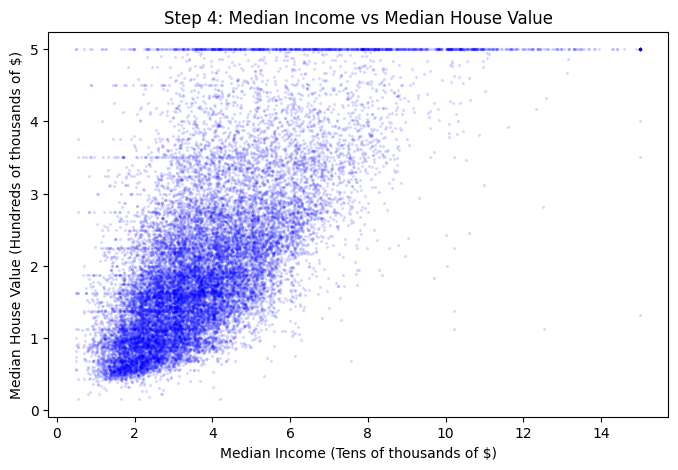

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, alpha=0.1, color='blue', s=2)
plt.title("Step 4: Median Income vs Median House Value")
plt.xlabel("Median Income (Tens of thousands of $)")
plt.ylabel("Median House Value (Hundreds of thousands of $)")
plt.show()

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("\n--- Step 5: Data Split ---\n")
print(f"Training observations: {len(X_train)} (Used to learn model parameters)")
print(f"Testing observations: {len(X_test)} (Used to evaluate performance on unseen data)")


--- Step 5: Data Split ---

Training observations: 16512 (Used to learn model parameters)
Testing observations: 4128 (Used to evaluate performance on unseen data)


In [14]:
model = LinearRegression()
model.fit(X_train, y_train)
intercept = model.intercept_
coefficient = model.coef_[0]

print("\n--- Step 6: Model Training ---\n")

print(f"Intercept: {intercept:.4f}")
print(f"Coefficient: {coefficient:.4f}")
print(f"Equation: Price = {coefficient:.4f} * (Median Income) + {intercept:.4f}")


--- Step 6: Model Training ---

Intercept: 0.4446
Coefficient: 0.4193
Equation: Price = 0.4193 * (Median Income) + 0.4446


In [18]:
y_pred = model.predict(X_test)
comparison_df = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
print("\n--- Step 7: Predictions Sample ---\n")
print(comparison_df.head(10))


--- Step 7: Predictions Sample ---

    Actual  Predicted
0  0.47700   1.149589
1  0.45800   1.506069
2  5.00001   1.903937
3  2.18600   2.850594
4  2.78000   2.006633
5  1.58700   2.421652
6  1.98200   2.576472
7  1.57500   1.992292
8  3.40000   2.458932
9  4.46600   3.846774


In [21]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n--- Step 8: Evaluation Metrics ---\n")
print(f"MAE: {mae:.4f} ")
print(f"MSE: {mse:.4f} ")
print(f"RMSE: {rmse:.4f} ")
print(f"R²: {r2:.4f} ")


--- Step 8: Evaluation Metrics ---

MAE: 0.6299 
MSE: 0.7091 
RMSE: 0.8421 
R²: 0.4589 


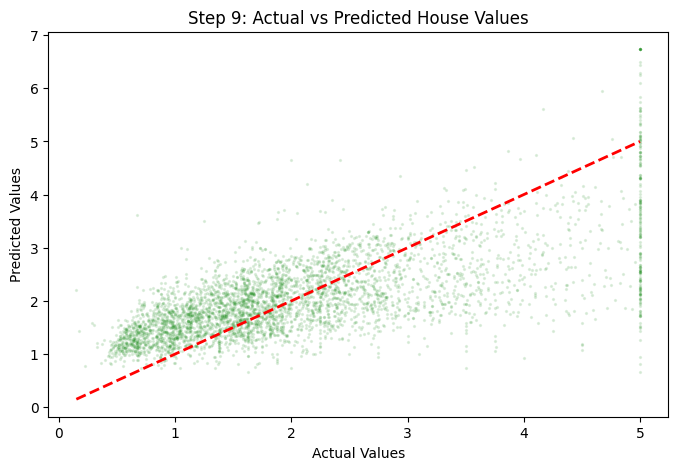

In [22]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.1, color='green', s=2)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2) # Reference line
plt.title("Step 9: Actual vs Predicted House Values")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.show()

In [24]:
new_income = np.array([[6.0]]) # Represents $60,000
new_prediction = model.predict(new_income)[0]
print("\n--- Step 10: New Prediction & Conclusion ---\n")
print(f"Predicted house value for a median income of 6.0 ($60k): {new_prediction:.4f} ($ {new_prediction * 100000:,.0f})")


--- Step 10: New Prediction & Conclusion ---

Predicted house value for a median income of 6.0 ($60k): 2.9606 ($ 296,063)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
